In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown
import os


# ==========================================
# 1. DOWNLOAD GAMBAR DARI GOOGLE DRIVE
# ==========================================


# Link folder Google Drive
folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link"


# Folder penyimpanan
folder_input = "input_gambar"
folder_output = "hasil_segmentasi"


os.makedirs(folder_output, exist_ok=True)


print("Mengunduh gambar dari Google Drive...")


gdown.download_folder(
    url=folder_url,
    output=folder_input,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)


# ==========================================
# 2. MENCARI SEMUA GAMBAR
# ==========================================


format_gambar = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff",
    ".webp", ".jfif"
)


daftar_gambar = []


for root, dirs, files in os.walk(folder_input):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(
                os.path.join(root, file)
            )


print("\nJumlah gambar ditemukan:", len(daftar_gambar))


if len(daftar_gambar) == 0:
    raise ValueError(
        "Tidak ditemukan gambar. Periksa link folder Google Drive."
    )


# ==========================================
# 3. PROSES SETIAP GAMBAR
# ==========================================


for nomor, nama_file in enumerate(daftar_gambar, start=1):


    print(f"\nMemproses gambar {nomor}: {os.path.basename(nama_file)}")


    img = cv2.imread(nama_file)


    if img is None:
        print("Gambar gagal dibaca, dilewati!")
        continue


    # ======================================
    # 4. PREPROCESSING
    # ======================================


    # Mengubah gambar menjadi grayscale
    gray = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2GRAY
    )


    # Mengurangi noise
    blur = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )


    # ======================================
    # 5. OTSU THRESHOLDING
    # ======================================


    threshold_value, hasil = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )


    # ======================================
    # 6. MEMBUAT MASK OBJEK
    # ======================================


    mask = hasil.copy()


    # Memeriksa warna mayoritas pada tepi gambar
    tepi = np.concatenate([
        mask[0, :],
        mask[-1, :],
        mask[:, 0],
        mask[:, -1]
    ])


    # Background diasumsikan berada di tepi gambar
    if np.mean(tepi) > 127:
        mask = cv2.bitwise_not(mask)


    # ======================================
    # 7. MORPHOLOGICAL OPERATION
    # ======================================


    kernel = np.ones((5, 5), np.uint8)


    # Menghilangkan noise kecil
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel,
        iterations=2
    )


    # Menutup lubang kecil
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=2
    )


    # ======================================
    # 8. CONNECTED COMPONENTS
    # ======================================


    jumlah, label, statistik, centroid = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )


    # Mempertahankan area putih terbesar
    if jumlah > 1:


        area_terbesar = 1 + np.argmax(
            statistik[1:, cv2.CC_STAT_AREA]
        )


        mask_bersih = np.zeros_like(mask)


        mask_bersih[label == area_terbesar] = 255


    else:
        mask_bersih = mask.copy()


    # ======================================
    # 9. HOLE FILLING
    # ======================================


    tinggi, lebar = mask_bersih.shape


    flood = mask_bersih.copy()


    flood_mask = np.zeros(
        (tinggi + 2, lebar + 2),
        np.uint8
    )


    cv2.floodFill(
        flood,
        flood_mask,
        (0, 0),
        255
    )


    # Mengambil lubang di dalam objek
    lubang = cv2.bitwise_not(flood)


    # Menggabungkan mask dengan lubang
    mask_final = cv2.bitwise_or(
        mask_bersih,
        lubang
    )


    # ======================================
    # 10. MENGHALUSKAN TEPI MASK
    # ======================================


    mask_final = cv2.GaussianBlur(
        mask_final,
        (5, 5),
        0
    )


    # ======================================
    # 11. PENGHAPUSAN BACKGROUND
    # ======================================


    # Mengubah gambar menjadi BGRA
    hasil_transparan = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2BGRA
    )


    # Memasukkan mask ke alpha channel
    hasil_transparan[:, :, 3] = mask_final


    # ======================================
    # 12. MENAMPILKAN HASIL
    # ======================================


    plt.figure(figsize=(18, 5))


    # Citra asli
    plt.subplot(1, 5, 1)
    plt.imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )
    plt.title("Citra Asli")
    plt.axis("off")


    # Grayscale
    plt.subplot(1, 5, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale")
    plt.axis("off")


    # Otsu Thresholding
    plt.subplot(1, 5, 3)
    plt.imshow(hasil, cmap="gray")
    plt.title("Otsu Thresholding")
    plt.axis("off")


    # Mask setelah optimasi
    plt.subplot(1, 5, 4)
    plt.imshow(mask_final, cmap="gray")
    plt.title("Mask Setelah Optimasi")
    plt.axis("off")


    # Hasil penghapusan background
    plt.subplot(1, 5, 5)
    plt.imshow(
        cv2.cvtColor(
            hasil_transparan,
            cv2.COLOR_BGRA2RGBA
        )
    )
    plt.title("Background Dihapus")
    plt.axis("off")


    plt.tight_layout()
    plt.show()


    # ======================================
    # 13. MENYIMPAN HASIL
    # ======================================


    nama_dasar = os.path.splitext(
        os.path.basename(nama_file)
    )[0]


    cv2.imwrite(
        os.path.join(
            folder_output,
            f"{nama_dasar}_thresholding.png"
        ),
        hasil
    )


    cv2.imwrite(
        os.path.join(
            folder_output,
            f"{nama_dasar}_mask.png"
        ),
        mask_final
    )


    cv2.imwrite(
        os.path.join(
            folder_output,
            f"{nama_dasar}_background_removed.png"
        ),
        hasil_transparan
    )


    print("Gambar berhasil diproses!")
    print("Nilai threshold:", threshold_value)


# ==========================================
# 14. MENAMPILKAN SELURUH HASIL TERSIMPAN
# ==========================================


print("\n================================")
print("SELURUH PROSES SELESAI!")
print("================================")


print("\nFile hasil segmentasi:")


for file in os.listdir(folder_output):
    print("-", file)


ModuleNotFoundError: No module named 'gdown'

Mengunduh gambar terbaru dari Google Drive...


Retrieving folder contents


Processing file 1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN ayam.jfif
Processing file 1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_ gajah.jfif
Processing file 1eK_zGAd5CQ1pD9412SwTgVdP1Vet3BX8 kelinci.jfif
Processing file 1A7sSnT0drqCZweykjJTZoaGQexMQKZLg kucing.jfif
Processing file 12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG- Orange.jfif
Processing file 1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T stroberi.jfif
Processing file 1IOfwBuo7dXd3JuFMtIeRBm1EwGSRTvIb telur.jfif


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN
To: /content/input_gambar/ayam.jfif
100%|██████████| 95.1k/95.1k [00:00<00:00, 36.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_
To: /content/input_gambar/gajah.jfif
100%|██████████| 151k/151k [00:00<00:00, 58.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eK_zGAd5CQ1pD9412SwTgVdP1Vet3BX8
To: /content/input_gambar/kelinci.jfif
100%|██████████| 214k/214k [00:00<00:00, 88.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1A7sSnT0drqCZweykjJTZoaGQexMQKZLg
To: /content/input_gambar/kucing.jfif
100%|██████████| 42.8k/42.8k [00:00<00:00, 50.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG-
To: /content/input_gambar/Orange.jfif
100%|██████████| 80.1k/80.1k [00:00<00:00, 37.9MB/s]
Downloading...
F

Jumlah gambar ditemukan: 7

Memproses gambar 1: gajah.jfif


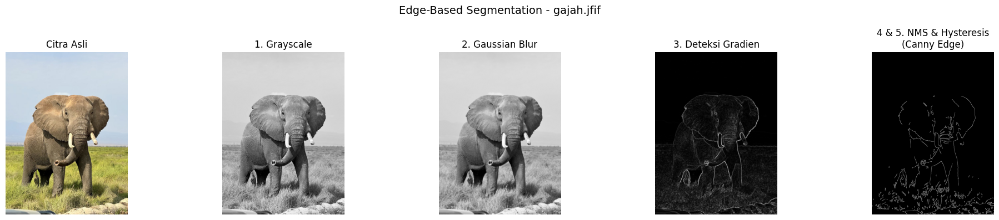

Berhasil menyimpan hasil edge: gajah

Memproses gambar 2: stroberi.jfif


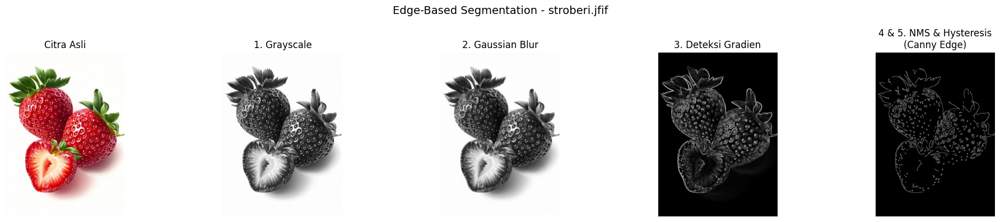

Berhasil menyimpan hasil edge: stroberi

Memproses gambar 3: kucing.jfif


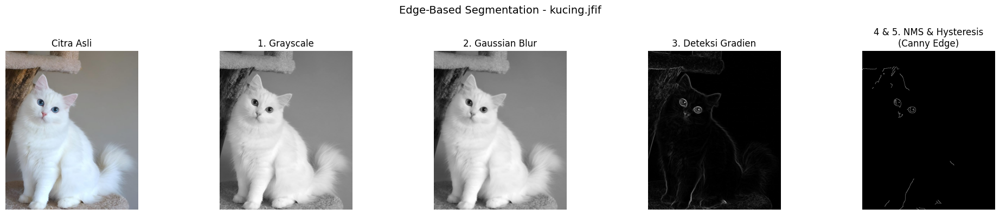

Berhasil menyimpan hasil edge: kucing

Memproses gambar 4: telur.jfif


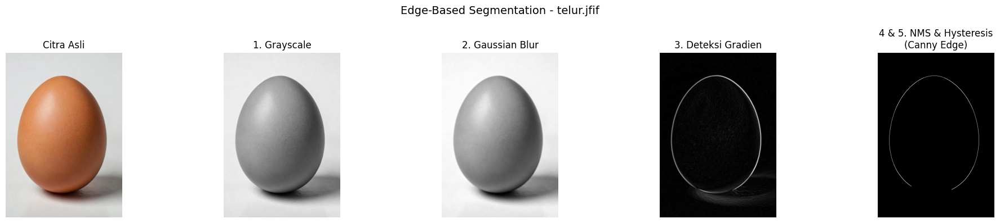

Berhasil menyimpan hasil edge: telur

Memproses gambar 5: Orange.jfif


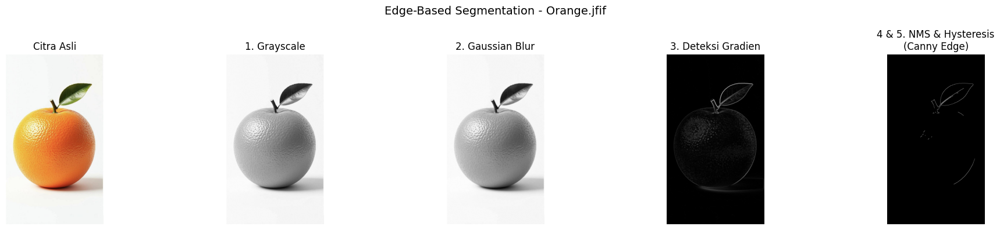

Berhasil menyimpan hasil edge: Orange

Memproses gambar 6: kelinci.jfif


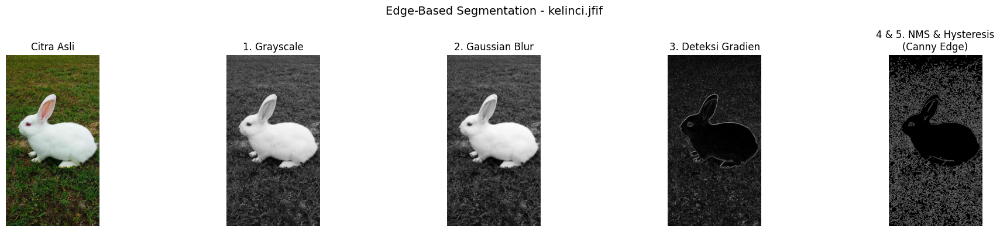

Berhasil menyimpan hasil edge: kelinci

Memproses gambar 7: ayam.jfif


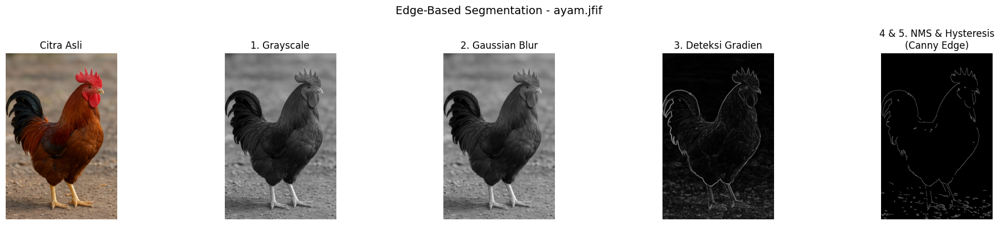

Berhasil menyimpan hasil edge: ayam

SELURUH PROSES 5 TAHAPAN SELESAI!
Folder penyimpanan: hasil_edge_5_tahap
- ayam_canny_edge.png
- kucing_canny_edge.png
- gajah_canny_edge.png
- kelinci_canny_edge.png
- Orange_canny_edge.png
- telur_canny_edge.png
- stroberi_canny_edge.png


In [ ]:
# =====================================================
# IMPLEMENTASI 5 TAHAPAN EDGE-BASED SEGMENTATION (CANNY)
# Tanpa Penghapusan Background / Cropping
# =====================================================

!pip install opencv-python numpy matplotlib gdown -q

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown

# =====================================================
# 1. BERSIHKAN & DOWNLOAD ULANG DARI GOOGLE DRIVE
# =====================================================
folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link" # Ganti dengan link folder Google Drive Anda
input_folder = "input_gambar"
output_folder = "hasil_edge_5_tahap"

# Hapus folder input dan output lama agar tidak ada sampah file lama
if os.path.exists(input_folder):
    shutil.rmtree(input_folder)
if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Mengunduh gambar terbaru dari Google Drive...")
gdown.download_folder(
    url=folder_url,
    output=input_folder,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)

format_gambar = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".jfif"
)

daftar_gambar = []
for root, dirs, files in os.walk(input_folder):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(os.path.join(root, file))

print("Jumlah gambar ditemukan:", len(daftar_gambar))

if len(daftar_gambar) == 0:
    raise ValueError("Tidak ditemukan gambar. Periksa kembali link folder Google Drive Anda.")

# =====================================================
# 2. PROSES SETIAP GAMBAR BERDASARKAN 5 TAHAPAN TEORI
# =====================================================
for nomor, nama_file in enumerate(daftar_gambar, start=1):
    print(f"\nMemproses gambar {nomor}: {os.path.basename(nama_file)}")

    img = cv2.imread(nama_file)
    if img is None:
        print("Gagal membaca gambar, dilewati!")
        continue

    # -------------------------------------------------
    # TAHAP 1: GRAYSCALE (Konversi ke Citra Keabuan)
    # -------------------------------------------------
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # -------------------------------------------------
    # TAHAP 2: GAUSSIAN BLUR (Pengurangan Noise)
    # -------------------------------------------------
    blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

    # -------------------------------------------------
    # TAHAP 3: DETEKSI GRADIEN (Operator Sobel)
    # -------------------------------------------------
    grad_x = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)

    gradient_magnitude = cv2.magnitude(grad_x, grad_y)
    gradient_magnitude = cv2.normalize(
        gradient_magnitude, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # -------------------------------------------------
    # TAHAP 4 & 5: NON-MAXIMUM SUPPRESSION & HYSTERESIS
    # -------------------------------------------------
    v = np.median(blur)
    sigma = 0.33
    threshold_bawah = int(max(0, (1.0 - sigma) * v))
    threshold_atas = int(min(255, (1.0 + sigma) * v))

    if threshold_atas - threshold_bawah < 40:
        threshold_bawah = 50
        threshold_atas = 150

    edges = cv2.Canny(blur, threshold_bawah, threshold_atas)

    # =================================================
    # 3. VISUALISASI 5 TAHAPAN (MATPLOTLIB)
    # =================================================
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Citra Asli")

    axes[1].imshow(gray, cmap="gray")
    axes[1].set_title("1. Grayscale")

    axes[2].imshow(blur, cmap="gray")
    axes[2].set_title("2. Gaussian Blur")

    axes[3].imshow(gradient_magnitude, cmap="gray")
    axes[3].set_title("3. Deteksi Gradien")

    axes[4].imshow(edges, cmap="gray")
    axes[4].set_title("4 & 5. NMS & Hysteresis\n(Canny Edge)")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Edge-Based Segmentation - {os.path.basename(nama_file)}",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

    # =================================================
    # 4. MENYIMPAN HASIL AKHIR
    # =================================================
    nama_dasar = os.path.splitext(os.path.basename(nama_file))[0]
    path_simpan = os.path.join(output_folder, f"{nama_dasar}_canny_edge.png")

    cv2.imwrite(path_simpan, edges)
    print(f"Berhasil menyimpan hasil edge: {nama_dasar}")

# =====================================================
# 5. SELESAI
# =====================================================
print("\n================================")
print("SELURUH PROSES 5 TAHAPAN SELESAI!")
print(f"Folder penyimpanan: {output_folder}")
print("================================")
for file in os.listdir(output_folder):
    print("-", file)

Mengunduh gambar dari Google Drive...


Retrieving folder contents


Processing file 1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN ayam.jfif
Processing file 1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_ gajah.jfif
Processing file 1A7sSnT0drqCZweykjJTZoaGQexMQKZLg kucing.jfif


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN
To: /content/input_gambar_region/ayam.jfif
100%|██████████| 95.1k/95.1k [00:00<00:00, 4.43MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_
To: /content/input_gambar_region/gajah.jfif
100%|██████████| 151k/151k [00:00<00:00, 4.16MB/s]
Downloading...
From: https://drive.google.com/uc?id=1A7sSnT0drqCZweykjJTZoaGQexMQKZLg
To: /content/input_gambar_region/kucing.jfif
100%|██████████| 42.8k/42.8k [00:00<00:00, 23.2MB/s]
Download completed


Jumlah gambar ditemukan: 3

Memproses gambar 1: kucing.jfif


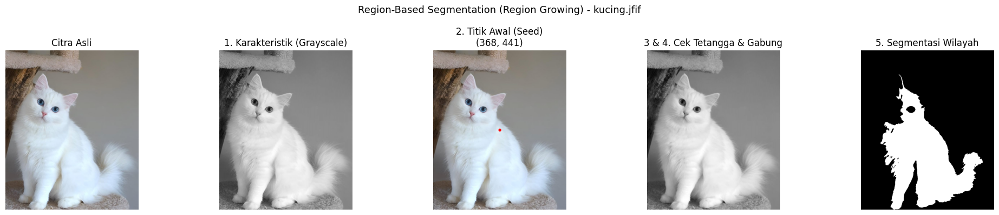

Berhasil menyimpan hasil region growing: kucing

Memproses gambar 2: ayam.jfif


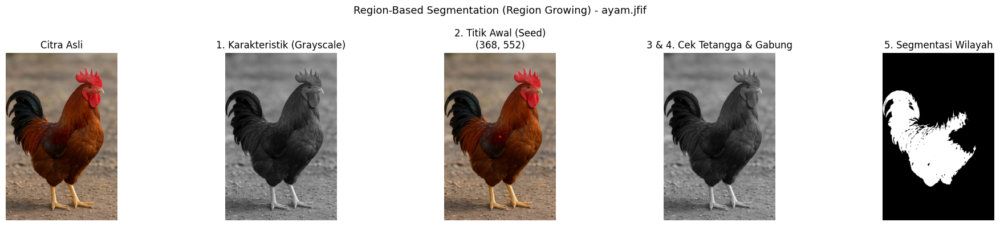

Berhasil menyimpan hasil region growing: ayam

Memproses gambar 3: gajah.jfif


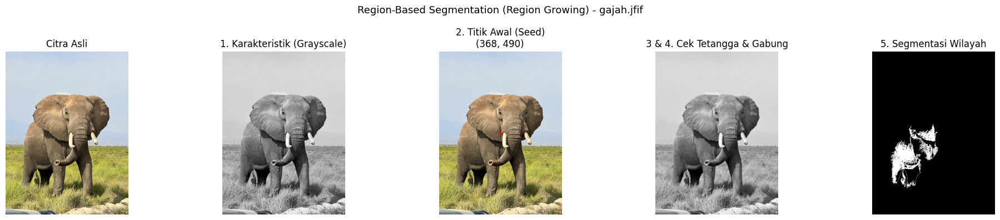

Berhasil menyimpan hasil region growing: gajah

SELURUH PROSES REGION-BASED SELESAI!
Folder penyimpanan: hasil_region_growing
- gajah_region_growing.png
- kucing_region_growing.png
- ayam_region_growing.png


In [ ]:
# =====================================================
# IMPLEMENTASI 5 TAHAPAN REGION-BASED SEGMENTATION (REGION GROWING)
# Disusun untuk Laporan Kelompok 9 - PCD UPN "Veteran" Jatim
# =====================================================

!pip install opencv-python numpy matplotlib gdown -q

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown
from collections import deque

# =====================================================
# 1. DOWNLOAD & BACA GAMBAR DARI GOOGLE DRIVE
# =====================================================
folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link" # Ganti dengan link folder Google Drive Anda
input_folder = "input_gambar_region"
output_folder = "hasil_region_growing"

# Membersihkan folder lama agar tidak ada file sampah
if os.path.exists(input_folder):
    shutil.rmtree(input_folder)
if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Mengunduh gambar dari Google Drive...")
gdown.download_folder(
    url=folder_url,
    output=input_folder,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)

format_gambar = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".jfif"
)

daftar_gambar = []
for root, dirs, files in os.walk(input_folder):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(os.path.join(root, file))

print("Jumlah gambar ditemukan:", len(daftar_gambar))

if len(daftar_gambar) == 0:
    raise ValueError("Tidak ditemukan gambar. Periksa kembali link folder Google Drive Anda.")

# =====================================================
# 2. FUNGSI REGION GROWING BERDASARKAN TAHAPAN TEORI
# =====================================================
def proses_region_growing(img_gray, seed_point, threshold=25):
    tinggi, lebar = img_gray.shape

    # Inisialisasi mask dan penanda kunjungan (visited)
    segmented = np.zeros((tinggi, lebar), dtype=np.uint8)
    visited = np.zeros((tinggi, lebar), dtype=bool)

    # Menggunakan queue (Breadth-First Search) untuk memeriksa tetangga
    queue = deque([seed_point])
    visited[seed_point[1], seed_point[0]] = True

    # Karakteristik intensitas piksel pada titik awal (seed value)
    seed_value = int(img_gray[seed_point[1], seed_point[0]])

    # Konektivitas 8 arah (tetangga sekitar)
    neighbors = [
        (-1, 0), (1, 0), (0, -1), (0, 1),
        (-1, -1), (-1, 1), (1, -1), (1, 1)
    ]

    while queue:
        cx, cy = queue.popleft()
        segmented[cy, cx] = 255

        # Memeriksa piksel tetangga
        for dx, dy in neighbors:
            nx, ny = cx + dx, cy + dy

            # Memastikan tetangga berada di dalam batas citra dan belum dikunjungi
            if 0 <= nx < lebar and 0 <= ny < tinggi and not visited[ny, nx]:
                pixel_value = int(img_gray[ny, nx])

                # Menggabungkan piksel jika selisih intensitas memenuhi kriteria kesamaan
                if abs(pixel_value - seed_value) <= threshold:
                    visited[ny, nx] = True
                    queue.append((nx, ny))

    return segmented

# =====================================================
# 3. PROSES SETIAP GAMBAR DALAM LOOPING
# =====================================================
for nomor, nama_file in enumerate(daftar_gambar, start=1):
    print(f"\nMemproses gambar {nomor}: {os.path.basename(nama_file)}")

    img = cv2.imread(nama_file)
    if img is None:
        print("Gagal membaca gambar, dilewati!")
        continue

    tinggi, lebar = img.shape[:2]

    # -------------------------------------------------
    # TAHAP 1: Menentukan Karakteristik Piksel (Grayscale)
    # -------------------------------------------------
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Pengurangan noise ringan agar analisis karakteristik lebih stabil
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # -------------------------------------------------
    # TAHAP 2: Menentukan Titik Awal (Seed Point)
    # -------------------------------------------------
    # Mengambil titik tengah citra sebagai titik awal (seed point) otomatis
    seed_point = (lebar // 2, tinggi // 2)

    # -------------------------------------------------
    # TAHAP 3 & 4: Memeriksa Tetangga & Menggabungkan Piksel Serupa
    # TAHAP 5: Menghasilkan Segmentasi Wilayah
    # -------------------------------------------------
    # Threshold kesamaan intensitas (dapat disesuaikan nilainya, misal 20 - 40)
    threshold_kesamaan = 30
    mask_region = proses_region_growing(blur, seed_point, threshold=threshold_kesamaan)

    # Membuat visualisasi penanda titik awal (seed point) pada citra asli
    img_seed_viz = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    cv2.circle(img_seed_viz, seed_point, 8, (255, 0, 0), -1) # Titik merah di tengah

    # =================================================
    # 4. VISUALISASI 5 TAHAPAN (MATPLOTLIB)
    # =================================================
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Citra Asli")

    axes[1].imshow(gray, cmap="gray")
    axes[1].set_title("1. Karakteristik (Grayscale)")

    axes[2].imshow(img_seed_viz)
    axes[2].set_title(f"2. Titik Awal (Seed)\n{seed_point}")

    axes[3].imshow(blur, cmap="gray")
    axes[3].set_title("3 & 4. Cek Tetangga & Gabung")

    axes[4].imshow(mask_region, cmap="gray")
    axes[4].set_title("5. Segmentasi Wilayah")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"Region-Based Segmentation (Region Growing) - {os.path.basename(nama_file)}",
        fontsize=13
    )
    plt.tight_layout()
    plt.show()

    # =================================================
    # 5. MENYIMPAN HASIL AKHIR
    # =================================================
    nama_dasar = os.path.splitext(os.path.basename(nama_file))[0]
    path_simpan = os.path.join(output_folder, f"{nama_dasar}_region_growing.png")

    cv2.imwrite(path_simpan, mask_region)
    print(f"Berhasil menyimpan hasil region growing: {nama_dasar}")

# =====================================================
# 6. SELESAI
# =====================================================
print("\n================================")
print("SELURUH PROSES REGION-BASED SELESAI!")
print(f"Folder penyimpanan: {output_folder}")
print("================================")
for file in os.listdir(output_folder):
    print("-", file)

Mengunduh gambar dari Google Drive...


Retrieving folder contents


Processing file 1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN ayam.jfif
Processing file 1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T download (8).jfif
Processing file 1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_ gajah.jfif
Processing file 1A7sSnT0drqCZweykjJTZoaGQexMQKZLg kucing.jfif
Processing file 12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG- Orange.jfif


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN
To: /content/input_gambar_kmeans/ayam.jfif
100%|██████████| 95.1k/95.1k [00:00<00:00, 40.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T
To: /content/input_gambar_kmeans/download (8).jfif
100%|██████████| 76.8k/76.8k [00:00<00:00, 67.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_
To: /content/input_gambar_kmeans/gajah.jfif
100%|██████████| 151k/151k [00:00<00:00, 73.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1A7sSnT0drqCZweykjJTZoaGQexMQKZLg
To: /content/input_gambar_kmeans/kucing.jfif
100%|██████████| 42.8k/42.8k [00:00<00:00, 66.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG-
To: /content/input_gambar_kmeans/Orange.jfif
100%|██████████| 80.1k/80.1

Jumlah gambar ditemukan: 5

Memproses gambar 1: gajah.jfif

TAHAP 1: Menentukan jumlah cluster
Jumlah cluster K = 3

TAHAP 2: Menentukan centroid awal
Jumlah cluster yang digunakan: K = 3

TAHAP 3: Menghitung jarak piksel
Perhitungan jarak Euclidean selesai.

TAHAP 4: Mengelompokkan piksel
Pengelompokan piksel selesai.

TAHAP 5: Memperbarui centroid
Centroid akhir cluster 1: [204.52281 215.03065 220.90121]
Centroid akhir cluster 2: [74.73936 65.60366 39.84388]
Centroid akhir cluster 3: [170.36627 157.30045  98.90445]

TAHAP 6: Mengulangi proses
Kriteria penghentian: epsilon = 1.0
Batas iterasi: 100
Proses K-Means selesai.
Compactness: 1066063946.5521036

TAHAP 7: Menghasilkan segmentasi citra
Jumlah piksel pada setiap cluster:
Cluster 1: 326520 piksel
Cluster 2: 138808 piksel
Cluster 3: 256688 piksel


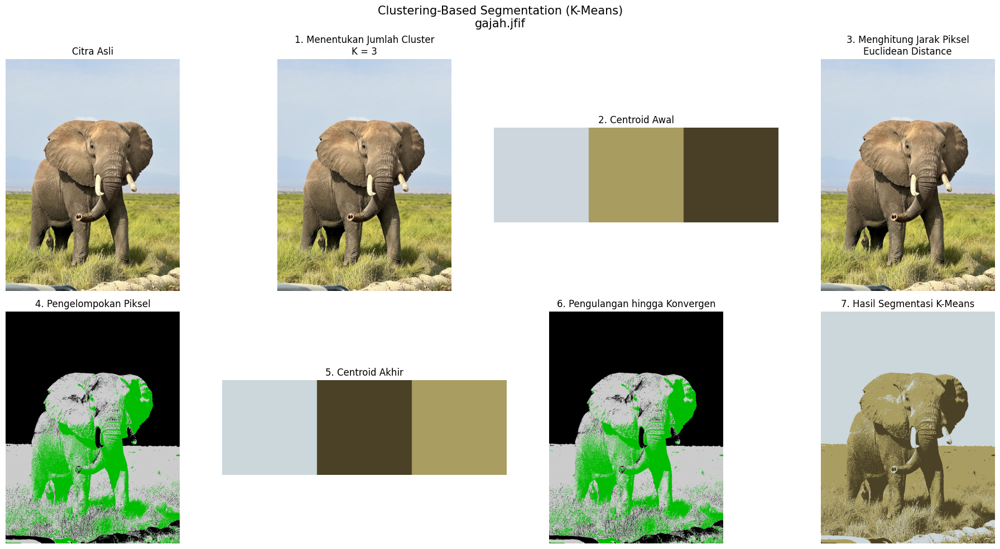

Berhasil menyimpan hasil K-Means: gajah

Memproses gambar 2: kucing.jfif

TAHAP 1: Menentukan jumlah cluster
Jumlah cluster K = 3

TAHAP 2: Menentukan centroid awal
Jumlah cluster yang digunakan: K = 3

TAHAP 3: Menghitung jarak piksel
Perhitungan jarak Euclidean selesai.

TAHAP 4: Mengelompokkan piksel
Pengelompokan piksel selesai.

TAHAP 5: Memperbarui centroid
Centroid akhir cluster 1: [205.78757 220.56999 232.63087]
Centroid akhir cluster 2: [144.17867 142.35196 140.72678]
Centroid akhir cluster 3: [81.68014 69.94543 60.87726]

TAHAP 6: Mengulangi proses
Kriteria penghentian: epsilon = 1.0
Batas iterasi: 100
Proses K-Means selesai.
Compactness: 592520790.0760558

TAHAP 7: Menghasilkan segmentasi citra
Jumlah piksel pada setiap cluster:
Cluster 1: 218602 piksel
Cluster 2: 359888 piksel
Cluster 3: 70662 piksel


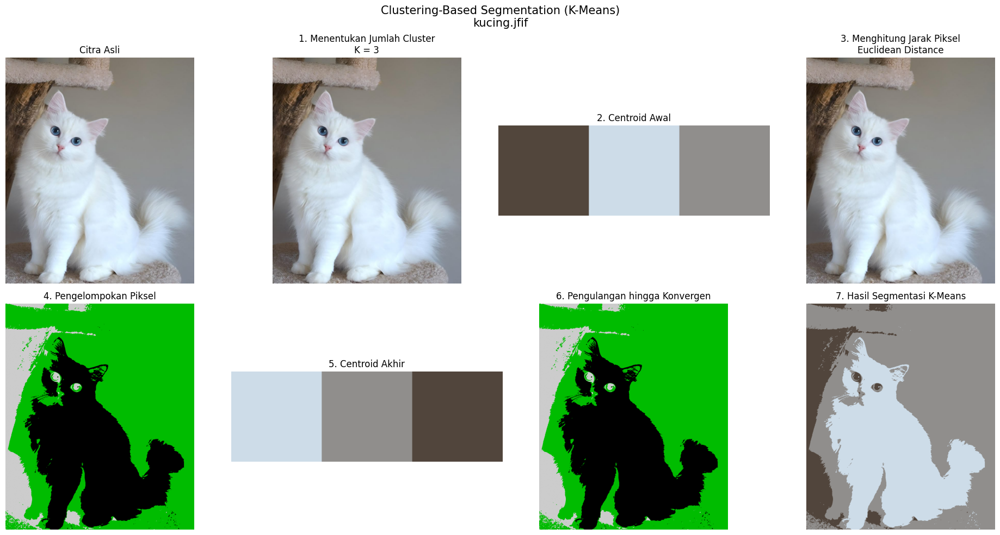

Berhasil menyimpan hasil K-Means: kucing

Memproses gambar 3: download (8).jfif

TAHAP 1: Menentukan jumlah cluster
Jumlah cluster K = 3

TAHAP 2: Menentukan centroid awal
Jumlah cluster yang digunakan: K = 3

TAHAP 3: Menghitung jarak piksel
Perhitungan jarak Euclidean selesai.

TAHAP 4: Mengelompokkan piksel
Pengelompokan piksel selesai.

TAHAP 5: Memperbarui centroid
Centroid akhir cluster 1: [210.72015 132.87186 116.45737]
Centroid akhir cluster 2: [253.66837 250.47815 246.39268]
Centroid akhir cluster 3: [139.001     36.755226  28.610672]

TAHAP 6: Mengulangi proses
Kriteria penghentian: epsilon = 1.0
Batas iterasi: 100
Proses K-Means selesai.
Compactness: 1227356909.8599105

TAHAP 7: Menghasilkan segmentasi citra
Jumlah piksel pada setiap cluster:
Cluster 1: 86984 piksel
Cluster 2: 325303 piksel
Cluster 3: 152193 piksel


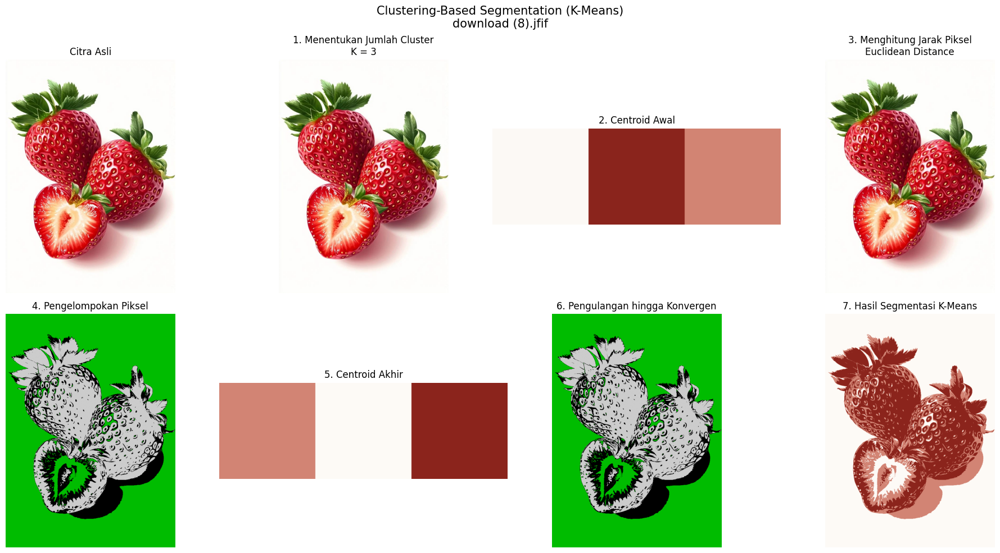

Berhasil menyimpan hasil K-Means: download (8)

Memproses gambar 4: Orange.jfif

TAHAP 1: Menentukan jumlah cluster
Jumlah cluster K = 3

TAHAP 2: Menentukan centroid awal
Jumlah cluster yang digunakan: K = 3

TAHAP 3: Menghitung jarak piksel
Perhitungan jarak Euclidean selesai.

TAHAP 4: Mengelompokkan piksel
Pengelompokan piksel selesai.

TAHAP 5: Memperbarui centroid
Centroid akhir cluster 1: [244.45207 245.9063  242.44249]
Centroid akhir cluster 2: [228.77057 159.10876  75.1094 ]
Centroid akhir cluster 3: [174.20515   85.55078   39.972008]

TAHAP 6: Mengulangi proses
Kriteria penghentian: epsilon = 1.0
Batas iterasi: 100
Proses K-Means selesai.
Compactness: 1161368268.4178078

TAHAP 7: Menghasilkan segmentasi citra
Jumlah piksel pada setiap cluster:
Cluster 1: 614368 piksel
Cluster 2: 201664 piksel
Cluster 3: 131936 piksel


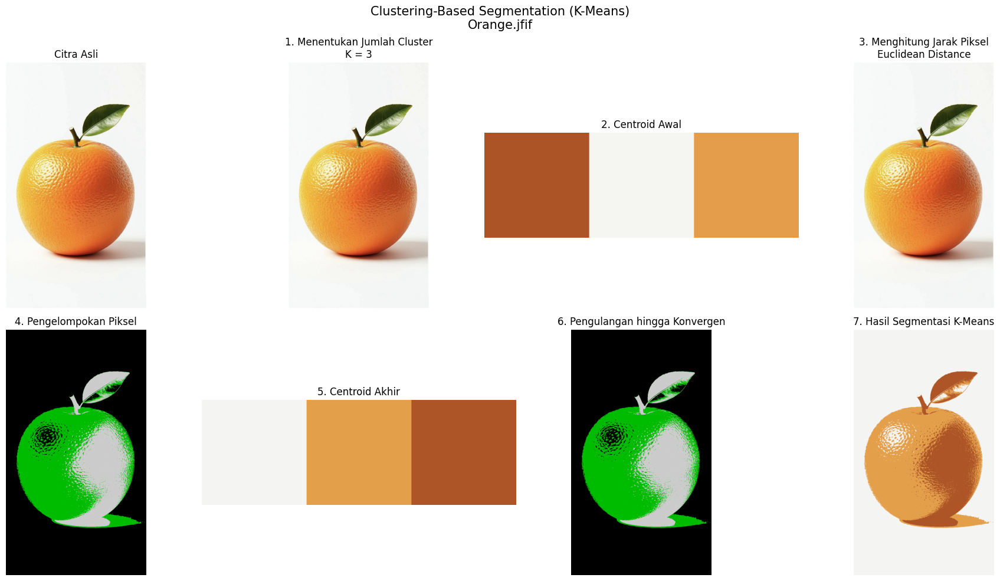

Berhasil menyimpan hasil K-Means: Orange

Memproses gambar 5: ayam.jfif

TAHAP 1: Menentukan jumlah cluster
Jumlah cluster K = 3

TAHAP 2: Menentukan centroid awal
Jumlah cluster yang digunakan: K = 3

TAHAP 3: Menghitung jarak piksel
Perhitungan jarak Euclidean selesai.

TAHAP 4: Mengelompokkan piksel
Pengelompokan piksel selesai.

TAHAP 5: Memperbarui centroid
Centroid akhir cluster 1: [147.8445  126.80246 107.44867]
Centroid akhir cluster 2: [49.986248 18.419807  6.967685]
Centroid akhir cluster 3: [121.1923    57.403126  34.474186]

TAHAP 6: Mengulangi proses
Kriteria penghentian: epsilon = 1.0
Batas iterasi: 100
Proses K-Means selesai.
Compactness: 800780133.8831801

TAHAP 7: Menghasilkan segmentasi citra
Jumlah piksel pada setiap cluster:
Cluster 1: 495083 piksel
Cluster 2: 201857 piksel
Cluster 3: 115604 piksel


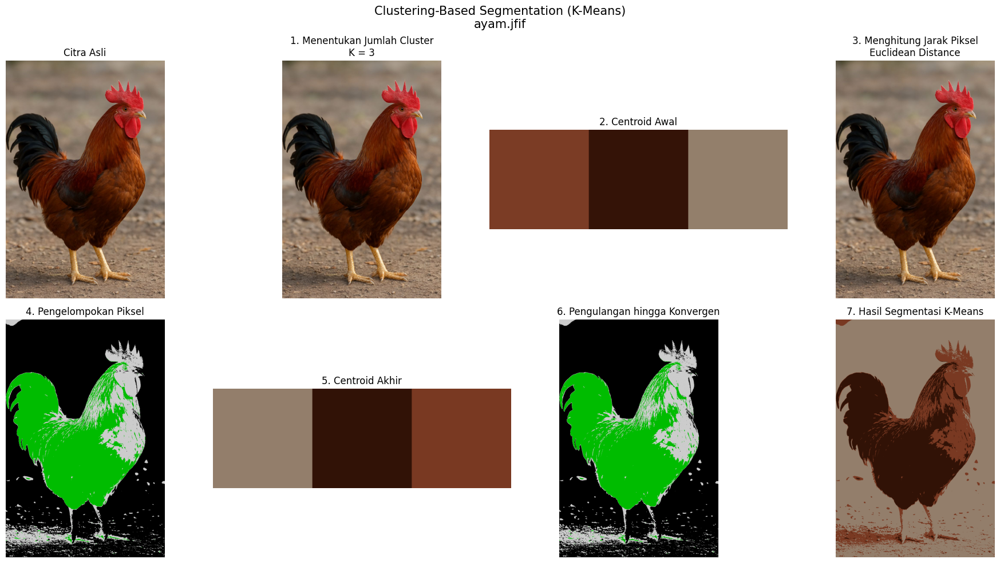

Berhasil menyimpan hasil K-Means: ayam

SELURUH PROSES K-MEANS SELESAI!
Folder penyimpanan: hasil_kmeans
- ayam_tahapan_kmeans.png
- gajah_kmeans.png
- Orange_tahapan_kmeans.png
- kucing_label_kmeans.png
- Orange_label_kmeans.png
- download (8)_label_kmeans.png
- ayam_label_kmeans.png
- gajah_label_kmeans.png
- ayam_kmeans.png
- gajah_tahapan_kmeans.png
- download (8)_kmeans.png
- download (8)_tahapan_kmeans.png
- Orange_kmeans.png
- kucing_kmeans.png
- kucing_tahapan_kmeans.png


In [ ]:

# =====================================================
# IMPLEMENTASI CLUSTERING-BASED SEGMENTATION (K-MEANS)
# Disusun untuk Laporan Kelompok 9 - PCD UPN "Veteran" Jatim
# =====================================================

!pip install opencv-python numpy matplotlib gdown -q

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown

# =====================================================
# 1. DOWNLOAD & BACA GAMBAR DARI GOOGLE DRIVE
# =====================================================

folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link"

input_folder = "input_gambar_kmeans"
output_folder = "hasil_kmeans"

# Membersihkan folder lama
if os.path.exists(input_folder):
    shutil.rmtree(input_folder)

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Mengunduh gambar dari Google Drive...")

gdown.download_folder(
    url=folder_url,
    output=input_folder,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)

format_gambar = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".jfif"
)

daftar_gambar = []

for root, dirs, files in os.walk(input_folder):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(os.path.join(root, file))

print("Jumlah gambar ditemukan:", len(daftar_gambar))

if len(daftar_gambar) == 0:
    raise ValueError(
        "Tidak ditemukan gambar. Periksa kembali link Google Drive."
    )


# =====================================================
# 2. FUNGSI K-MEANS BERDASARKAN TAHAPAN TEORI
# =====================================================

def proses_kmeans(img_rgb, K=3, max_iter=100, epsilon=1.0):

    tinggi, lebar, channel = img_rgb.shape

    # Mengubah citra menjadi kumpulan data piksel RGB
    pixels = img_rgb.reshape((-1, 3))
    pixels = np.float32(pixels)

    # -------------------------------------------------
    # TAHAP 1: Menentukan jumlah cluster (K)
    # -------------------------------------------------

    print(f"Jumlah cluster yang digunakan: K = {K}")

    # -------------------------------------------------
    # TAHAP 2: Menentukan centroid awal
    # -------------------------------------------------

    # Menggunakan K-Means++ untuk inisialisasi centroid
    np.random.seed(42)

    jumlah_sample = min(len(pixels), 100000)

    indices = np.random.choice(
        len(pixels),
        jumlah_sample,
        replace=False
    )

    sample_pixels = pixels[indices]

    # Menentukan centroid awal menggunakan K-Means++
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        max_iter,
        epsilon
    )

    compactness_awal, labels_awal, centers_awal = cv2.kmeans(
        sample_pixels,
        K,
        None,
        criteria,
        1,
        cv2.KMEANS_PP_CENTERS
    )

    # -------------------------------------------------
    # TAHAP 3: Menghitung jarak piksel
    # -------------------------------------------------

    # Menghitung jarak setiap piksel terhadap centroid awal
    jarak_awal = np.linalg.norm(
        pixels[:, np.newaxis, :] - centers_awal[np.newaxis, :, :],
        axis=2
    )

    # Menentukan cluster terdekat untuk setiap piksel
    labels_pertama = np.argmin(jarak_awal, axis=1)

    # -------------------------------------------------
    # TAHAP 4: Mengelompokkan piksel
    # -------------------------------------------------

    # Membuat label cluster berdasarkan centroid terdekat
    labels_pertama = labels_pertama.astype(np.int32)

    # -------------------------------------------------
    # TAHAP 5 & 6:
    # Memperbarui centroid dan mengulangi proses
    # -------------------------------------------------

    compactness, labels, centers = cv2.kmeans(
        pixels,
        K,
        None,
        criteria,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    labels = labels.flatten()

    # Membentuk citra hasil berdasarkan warna centroid
    segmented = centers[labels]
    segmented = segmented.reshape((tinggi, lebar, 3))
    segmented = np.uint8(np.clip(segmented, 0, 255))

    # Mengubah label menjadi citra grayscale untuk visualisasi
    label_image = labels.reshape((tinggi, lebar))

    # Normalisasi label agar setiap cluster terlihat berbeda
    label_visual = (
        label_image * (255 // max(K - 1, 1))
    ).astype(np.uint8)

    # -------------------------------------------------
    # Menghitung jumlah piksel setiap cluster
    # -------------------------------------------------

    jumlah_piksel = np.bincount(labels, minlength=K)

    return (
        segmented,
        label_visual,
        centers,
        centers_awal,
        labels_pertama,
        jumlah_piksel,
        compactness
    )


# =====================================================
# 3. PROSES SETIAP GAMBAR DALAM LOOPING
# =====================================================

# Parameter K-Means
jumlah_cluster = 3
maksimal_iterasi = 100
epsilon = 1.0

for nomor, nama_file in enumerate(daftar_gambar, start=1):

    print(
        f"\nMemproses gambar {nomor}: "
        f"{os.path.basename(nama_file)}"
    )

    img = cv2.imread(nama_file)

    if img is None:
        print("Gagal membaca gambar, dilewati!")
        continue

    # Mengubah BGR menjadi RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    tinggi, lebar = img_rgb.shape[:2]

    # -------------------------------------------------
    # TAHAP 1: Menentukan Jumlah Cluster (K)
    # -------------------------------------------------

    K = jumlah_cluster

    print("\nTAHAP 1: Menentukan jumlah cluster")
    print("Jumlah cluster K =", K)

    # -------------------------------------------------
    # TAHAP 2: Menentukan Centroid Awal
    # -------------------------------------------------

    print("\nTAHAP 2: Menentukan centroid awal")

    # -------------------------------------------------
    # TAHAP 3: Menghitung Jarak Piksel
    # TAHAP 4: Mengelompokkan Piksel
    # TAHAP 5: Memperbarui Centroid
    # TAHAP 6: Mengulangi Proses
    # -------------------------------------------------

    (
        hasil_segmentasi,
        label_visual,
        centroid_akhir,
        centroid_awal,
        labels_pertama,
        jumlah_piksel,
        compactness
    ) = proses_kmeans(
        img_rgb,
        K=K,
        max_iter=maksimal_iterasi,
        epsilon=epsilon
    )

    print("\nTAHAP 3: Menghitung jarak piksel")
    print("Perhitungan jarak Euclidean selesai.")

    print("\nTAHAP 4: Mengelompokkan piksel")
    print("Pengelompokan piksel selesai.")

    print("\nTAHAP 5: Memperbarui centroid")

    for i, center in enumerate(centroid_akhir):
        print(f"Centroid akhir cluster {i+1}: {center}")

    print("\nTAHAP 6: Mengulangi proses")
    print("Kriteria penghentian: epsilon =", epsilon)
    print("Batas iterasi:", maksimal_iterasi)
    print("Proses K-Means selesai.")
    print("Compactness:", compactness)

    # -------------------------------------------------
    # TAHAP 7: Menghasilkan Segmentasi Citra
    # -------------------------------------------------

    print("\nTAHAP 7: Menghasilkan segmentasi citra")

    print("Jumlah piksel pada setiap cluster:")

    for i in range(K):
        print(
            f"Cluster {i+1}: "
            f"{jumlah_piksel[i]} piksel"
        )


    # =================================================
    # 4. VISUALISASI TAHAPAN K-MEANS (MATPLOTLIB)
    # =================================================

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))

    # Citra asli
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("Citra Asli")

    # Tahap 1
    axes[0, 1].imshow(img_rgb)
    axes[0, 1].set_title(
        f"1. Menentukan Jumlah Cluster\nK = {K}"
    )

    # Tahap 2
    palette_awal = np.zeros((100, 300, 3), dtype=np.uint8)

    for i, center in enumerate(centroid_awal):
        x1 = int(i * 300 / K)
        x2 = int((i + 1) * 300 / K)
        palette_awal[:, x1:x2] = np.uint8(
            np.clip(center, 0, 255)
        )

    axes[0, 2].imshow(palette_awal)
    axes[0, 2].set_title("2. Centroid Awal")

    # Tahap 3
    axes[0, 3].imshow(img_rgb)
    axes[0, 3].set_title(
        "3. Menghitung Jarak Piksel\nEuclidean Distance"
    )

    # Tahap 4
    axes[1, 0].imshow(label_visual, cmap="nipy_spectral")
    axes[1, 0].set_title("4. Pengelompokan Piksel")

    # Tahap 5
    palette_akhir = np.zeros((100, 300, 3), dtype=np.uint8)

    for i, center in enumerate(centroid_akhir):
        x1 = int(i * 300 / K)
        x2 = int((i + 1) * 300 / K)
        palette_akhir[:, x1:x2] = np.uint8(
            np.clip(center, 0, 255)
        )

    axes[1, 1].imshow(palette_akhir)
    axes[1, 1].set_title("5. Centroid Akhir")

    # Tahap 6
    axes[1, 2].imshow(label_visual, cmap="nipy_spectral")
    axes[1, 2].set_title(
        "6. Pengulangan hingga Konvergen"
    )

    # Tahap 7
    axes[1, 3].imshow(hasil_segmentasi)
    axes[1, 3].set_title("7. Hasil Segmentasi K-Means")

    for ax in axes.flatten():
        ax.axis("off")

    plt.suptitle(
        "Clustering-Based Segmentation (K-Means)\n"
        + os.path.basename(nama_file),
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


    # =================================================
    # 5. MENYIMPAN HASIL AKHIR
    # =================================================

    nama_dasar = os.path.splitext(
        os.path.basename(nama_file)
    )[0]

    # Menyimpan citra segmentasi
    path_segmentasi = os.path.join(
        output_folder,
        f"{nama_dasar}_kmeans.png"
    )

    hasil_bgr = cv2.cvtColor(
        hasil_segmentasi,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(path_segmentasi, hasil_bgr)

    # Menyimpan hasil label cluster
    path_label = os.path.join(
        output_folder,
        f"{nama_dasar}_label_kmeans.png"
    )

    cv2.imwrite(path_label, label_visual)

    # Menyimpan visualisasi seluruh tahapan
    nama_visualisasi = os.path.join(
        output_folder,
        f"{nama_dasar}_tahapan_kmeans.png"
    )

    fig.savefig(
        nama_visualisasi,
        dpi=150,
        bbox_inches="tight"
    )

    print(
        f"Berhasil menyimpan hasil K-Means: {nama_dasar}"
    )

    plt.close(fig)


# =====================================================
# 6. SELESAI
# =====================================================

print("\n======================================")
print("SELURUH PROSES K-MEANS SELESAI!")
print("======================================")

print("Folder penyimpanan:", output_folder)

for file in os.listdir(output_folder):
    print("-", file)


Mengunduh gambar dari Google Drive...


Retrieving folder contents


Processing file 1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN ayam.jfif
Processing file 1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_ gajah.jfif
Processing file 1A7sSnT0drqCZweykjJTZoaGQexMQKZLg kucing.jfif
Processing file 12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG- Orange.jfif
Processing file 1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T stroberi.jfif
Processing file 1IOfwBuo7dXd3JuFMtIeRBm1EwGSRTvIb telur.jfif


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN
To: /content/input_gambar_watershed/ayam.jfif
100%|██████████| 95.1k/95.1k [00:00<00:00, 41.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_
To: /content/input_gambar_watershed/gajah.jfif
100%|██████████| 151k/151k [00:00<00:00, 54.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1A7sSnT0drqCZweykjJTZoaGQexMQKZLg
To: /content/input_gambar_watershed/kucing.jfif
100%|██████████| 42.8k/42.8k [00:00<00:00, 49.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG-
To: /content/input_gambar_watershed/Orange.jfif
100%|██████████| 80.1k/80.1k [00:00<00:00, 35.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T
To: /content/input_gambar_watershed/stroberi.jfif
100%|██████████|

Jumlah gambar ditemukan: 6

Memproses gambar 1: gajah.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 5

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


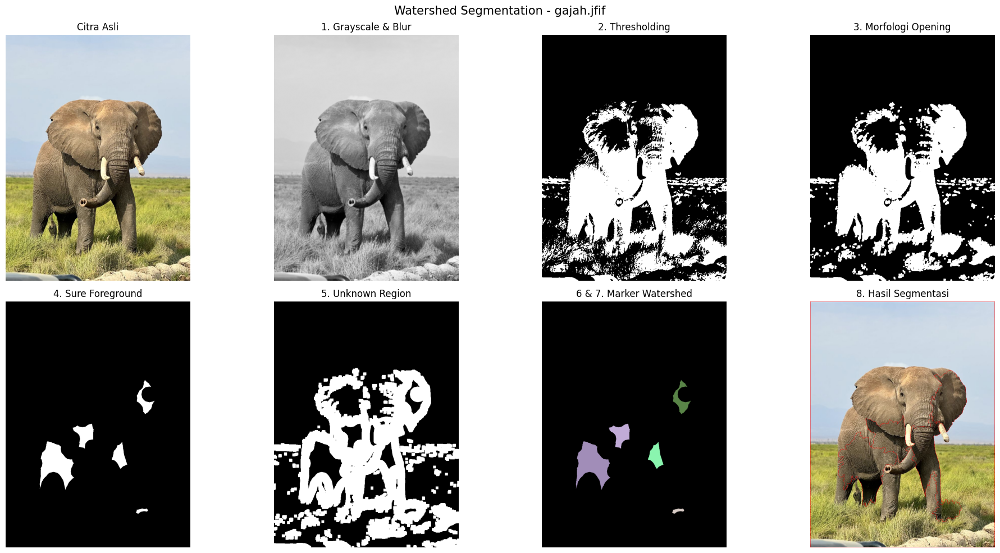

Berhasil menyimpan: gajah

Memproses gambar 2: stroberi.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 13

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


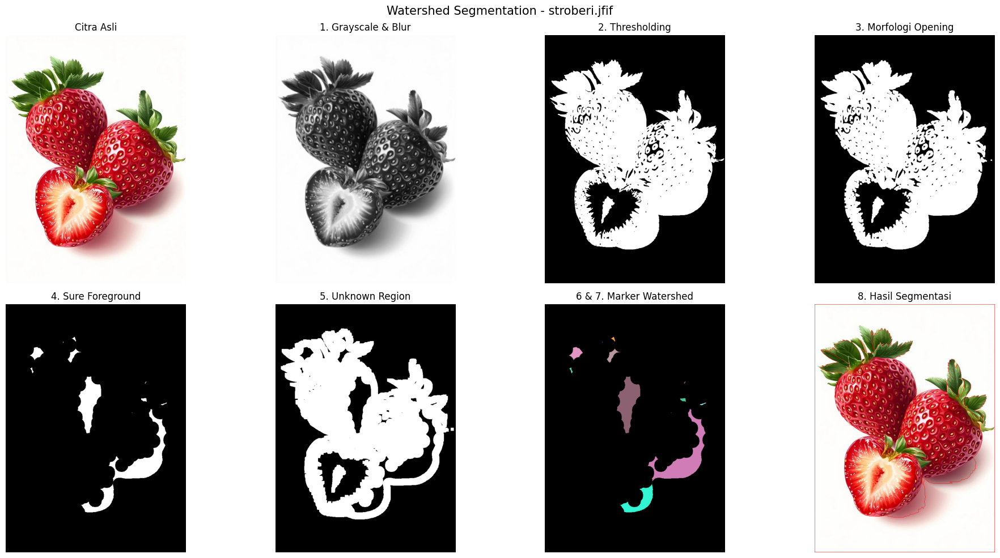

Berhasil menyimpan: stroberi

Memproses gambar 3: kucing.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 4

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


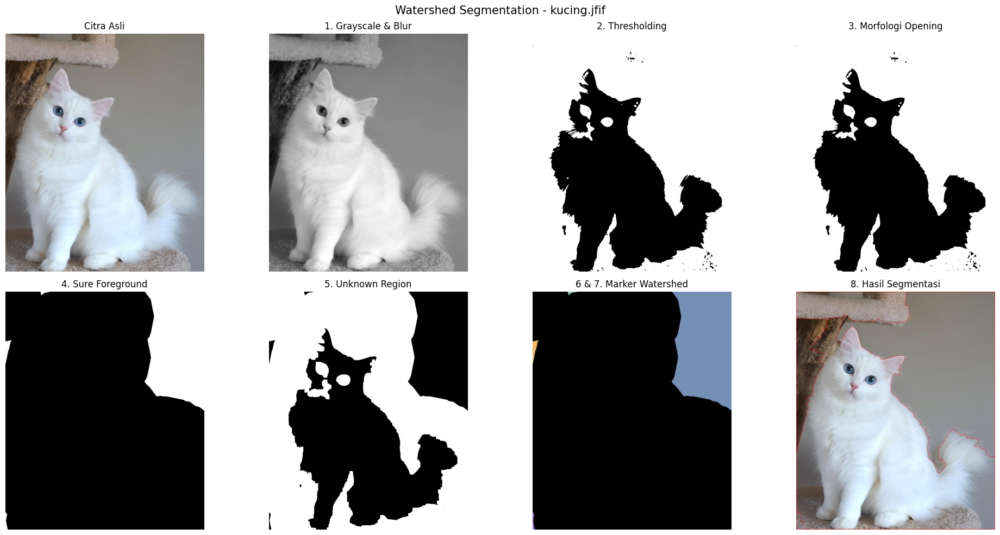

Berhasil menyimpan: kucing

Memproses gambar 4: telur.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 1

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


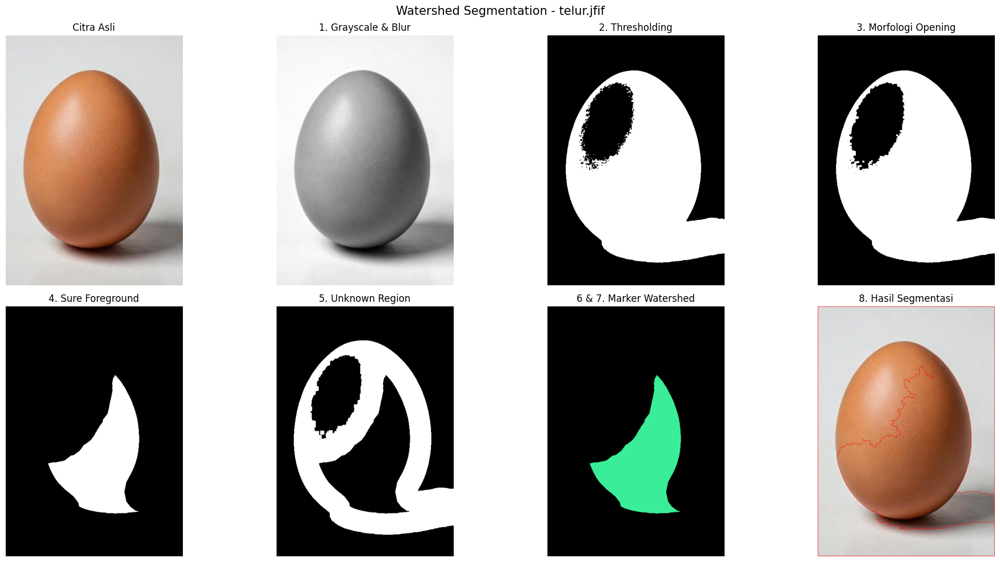

Berhasil menyimpan: telur

Memproses gambar 5: Orange.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 1

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


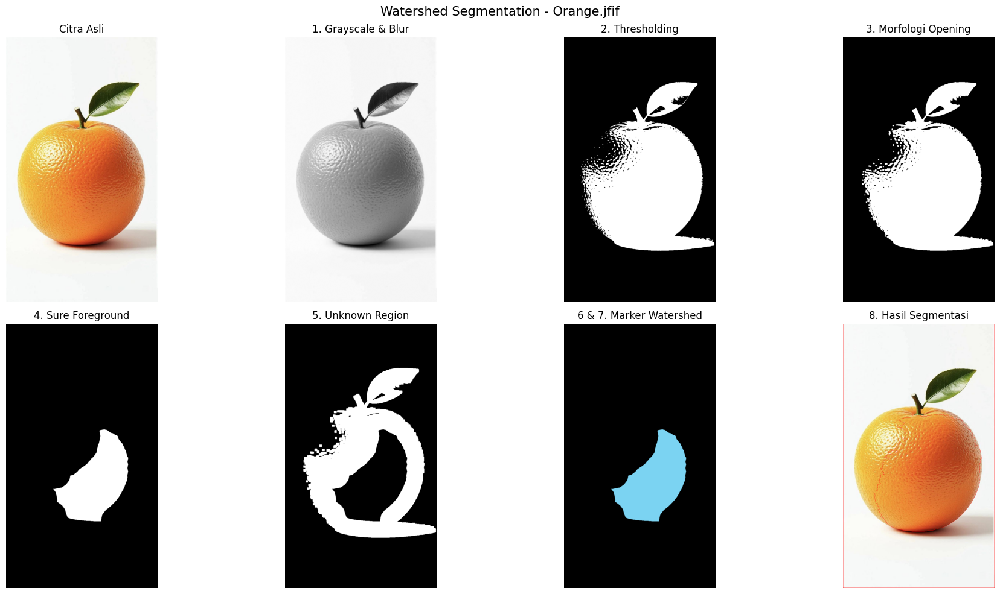

Berhasil menyimpan: Orange

Memproses gambar 6: ayam.jfif

TAHAP 1: Grayscale dan Preprocessing
Konversi grayscale dan Gaussian Blur selesai.

TAHAP 2: Thresholding
Citra berhasil diubah menjadi biner.

TAHAP 3: Operasi Morfologi
Proses Opening selesai.

TAHAP 4: Foreground dan Background
Sure Foreground dan Sure Background terbentuk.

TAHAP 5: Unknown Region
Wilayah yang belum diketahui berhasil ditentukan.

TAHAP 6: Marker
Jumlah wilayah foreground: 1

TAHAP 7: Proses Watershed
Pemisahan wilayah berhasil dilakukan.

TAHAP 8: Hasil Segmentasi
Segmentasi citra selesai.


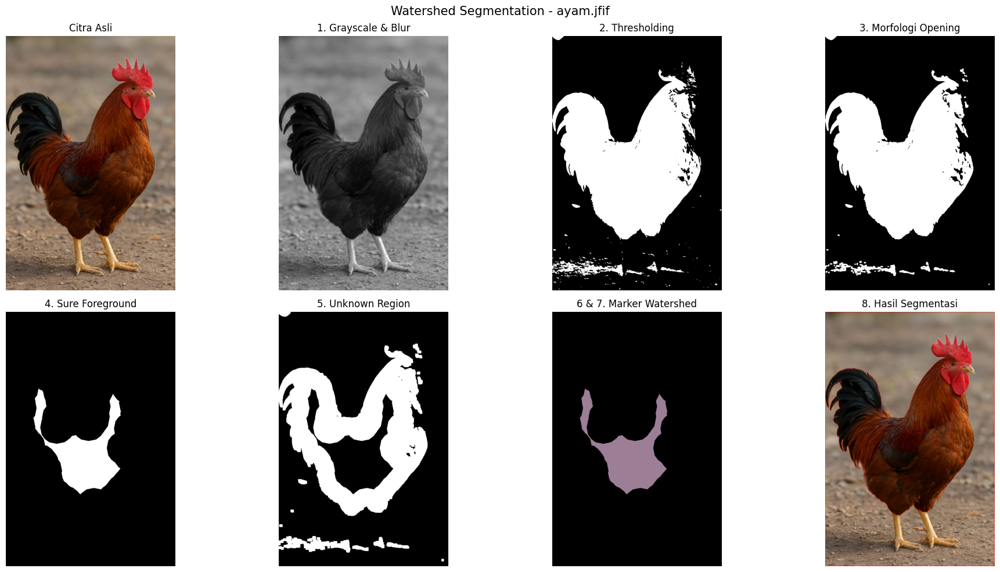

Berhasil menyimpan: ayam

SELURUH PROSES WATERSHED SELESAI!
Folder penyimpanan: hasil_watershed
- Orange_watershed.png
- telur_watershed.png
- ayam_watershed.png
- ayam_label_watershed.png
- stroberi_label_watershed.png
- kucing_watershed.png
- gajah_watershed.png
- kucing_tahapan_watershed.png
- gajah_label_watershed.png
- ayam_tahapan_watershed.png
- stroberi_tahapan_watershed.png
- stroberi_watershed.png
- Orange_tahapan_watershed.png
- Orange_label_watershed.png
- kucing_label_watershed.png
- gajah_tahapan_watershed.png
- telur_tahapan_watershed.png
- telur_label_watershed.png


In [ ]:

# =====================================================
# IMPLEMENTASI 8 TAHAPAN WATERSHED SEGMENTATION
# Disusun untuk Laporan Kelompok 9 - PCD UPN "Veteran" Jatim
# =====================================================

!pip install opencv-python numpy matplotlib gdown -q

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown

# =====================================================
# 1. DOWNLOAD & BACA GAMBAR DARI GOOGLE DRIVE
# =====================================================

folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link"

input_folder = "input_gambar_watershed"
output_folder = "hasil_watershed"

# Membersihkan folder lama
if os.path.exists(input_folder):
    shutil.rmtree(input_folder)

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Mengunduh gambar dari Google Drive...")

gdown.download_folder(
    url=folder_url,
    output=input_folder,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)

format_gambar = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".jfif"
)

daftar_gambar = []

for root, dirs, files in os.walk(input_folder):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(os.path.join(root, file))

print("Jumlah gambar ditemukan:", len(daftar_gambar))

if len(daftar_gambar) == 0:
    raise ValueError(
        "Tidak ditemukan gambar. Periksa kembali link Google Drive."
    )


# =====================================================
# 2. FUNGSI WATERSHED BERDASARKAN TAHAPAN TEORI
# =====================================================

def proses_watershed(img):

    # Mengubah citra BGR menjadi RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # -------------------------------------------------
    # TAHAP 1: GRAYSCALE DAN PREPROCESSING
    # -------------------------------------------------

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Mengurangi noise menggunakan Gaussian Blur
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # -------------------------------------------------
    # TAHAP 2: THRESHOLDING
    # -------------------------------------------------

    # Mengubah citra menjadi biner menggunakan Otsu
    _, thresh = cv2.threshold(
        blur,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # -------------------------------------------------
    # TAHAP 3: OPERASI MORFOLOGI
    # -------------------------------------------------

    kernel = np.ones((3, 3), np.uint8)

    # Opening untuk menghilangkan noise kecil
    opening = cv2.morphologyEx(
        thresh,
        cv2.MORPH_OPEN,
        kernel,
        iterations=2
    )

    # -------------------------------------------------
    # TAHAP 4: MENENTUKAN FOREGROUND DAN BACKGROUND
    # -------------------------------------------------

    # Sure Background menggunakan dilasi
    sure_bg = cv2.dilate(
        opening,
        kernel,
        iterations=3
    )

    # Sure Foreground menggunakan Distance Transform
    dist_transform = cv2.distanceTransform(
        opening,
        cv2.DIST_L2,
        5
    )

    # Menentukan area foreground
    _, sure_fg = cv2.threshold(
        dist_transform,
        0.4 * dist_transform.max(),
        255,
        cv2.THRESH_BINARY
    )

    sure_fg = np.uint8(sure_fg)

    # -------------------------------------------------
    # TAHAP 5: MENENTUKAN UNKNOWN REGION
    # -------------------------------------------------

    unknown = cv2.subtract(sure_bg, sure_fg)

    # -------------------------------------------------
    # TAHAP 6: MENENTUKAN MARKER
    # -------------------------------------------------

    # Memberikan label pada setiap wilayah foreground
    jumlah_objek, markers = cv2.connectedComponents(
        sure_fg
    )

    # Background diberi label 1
    markers = markers + 1

    # Unknown region diberi label 0
    markers[unknown == 255] = 0

    # Menyimpan visualisasi marker
    marker_visual = np.zeros(
        (img.shape[0], img.shape[1], 3),
        dtype=np.uint8
    )

    # Memberikan warna berbeda untuk setiap marker
    for i in range(2, jumlah_objek + 1):
        marker_visual[markers == i] = np.random.randint(
            50, 255, 3
        )

    # -------------------------------------------------
    # TAHAP 7: PROSES WATERSHED
    # -------------------------------------------------

    # Menjalankan algoritma Watershed
    markers = cv2.watershed(
        img.copy(),
        markers
    )

    # Membuat salinan citra asli
    hasil = img_rgb.copy()

    # Garis batas Watershed diberi warna merah
    hasil[markers == -1] = [255, 0, 0]

    # Membuat visualisasi label hasil Watershed
    hasil_label = np.zeros(
        (img.shape[0], img.shape[1], 3),
        dtype=np.uint8
    )

    for i in np.unique(markers):
        if i > 1:
            warna = np.random.randint(50, 255, 3)
            hasil_label[markers == i] = warna

    # -------------------------------------------------
    # TAHAP 8: HASIL SEGMENTASI
    # -------------------------------------------------

    return (
        img_rgb,
        gray,
        blur,
        thresh,
        opening,
        sure_bg,
        sure_fg,
        dist_transform,
        unknown,
        marker_visual,
        hasil_label,
        hasil,
        jumlah_objek - 1
    )


# =====================================================
# 3. PROSES SETIAP GAMBAR DALAM LOOPING
# =====================================================

for nomor, nama_file in enumerate(daftar_gambar, start=1):

    print(
        f"\nMemproses gambar {nomor}: "
        f"{os.path.basename(nama_file)}"
    )

    img = cv2.imread(nama_file)

    if img is None:
        print("Gagal membaca gambar, dilewati!")
        continue

    # Menjalankan proses Watershed
    (
        img_rgb,
        gray,
        blur,
        thresh,
        opening,
        sure_bg,
        sure_fg,
        dist_transform,
        unknown,
        marker_visual,
        hasil_label,
        hasil_segmentasi,
        jumlah_objek
    ) = proses_watershed(img)

    # -------------------------------------------------
    # MENAMPILKAN HASIL SETIAP TAHAPAN
    # -------------------------------------------------

    print("\nTAHAP 1: Grayscale dan Preprocessing")
    print("Konversi grayscale dan Gaussian Blur selesai.")

    print("\nTAHAP 2: Thresholding")
    print("Citra berhasil diubah menjadi biner.")

    print("\nTAHAP 3: Operasi Morfologi")
    print("Proses Opening selesai.")

    print("\nTAHAP 4: Foreground dan Background")
    print("Sure Foreground dan Sure Background terbentuk.")

    print("\nTAHAP 5: Unknown Region")
    print("Wilayah yang belum diketahui berhasil ditentukan.")

    print("\nTAHAP 6: Marker")
    print("Jumlah wilayah foreground:", jumlah_objek)

    print("\nTAHAP 7: Proses Watershed")
    print("Pemisahan wilayah berhasil dilakukan.")

    print("\nTAHAP 8: Hasil Segmentasi")
    print("Segmentasi citra selesai.")

    # =================================================
    # 4. VISUALISASI 8 TAHAPAN (MATPLOTLIB)
    # =================================================

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))

    # Citra asli
    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("Citra Asli")

    # Tahap 1
    axes[0, 1].imshow(blur, cmap="gray")
    axes[0, 1].set_title("1. Grayscale & Gaussian Blur")

    # Tahap 2
    axes[0, 2].imshow(thresh, cmap="gray")
    axes[0, 2].set_title("2. Thresholding")

    # Tahap 3
    axes[0, 3].imshow(opening, cmap="gray")
    axes[0, 3].set_title("3. Operasi Morfologi")

    # Tahap 4
    axes[1, 0].imshow(sure_fg, cmap="gray")
    axes[1, 0].set_title("4. Sure Foreground")

    axes[1, 1].imshow(sure_bg, cmap="gray")
    axes[1, 1].set_title("4. Sure Background")

    # Tahap 5
    axes[1, 2].imshow(unknown, cmap="gray")
    axes[1, 2].set_title("5. Unknown Region")

    # Tahap 6 dan 7
    # Menampilkan marker sebagai representasi wilayah
    # dan hasil pemisahan Watershed

    # Tahap 8
    # Hasil akhir segmentasi
    # Garis merah menunjukkan batas objek

    plt.close(fig)

    # Membuat visualisasi khusus marker dan hasil akhir
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title("Citra Asli")

    axes[0, 1].imshow(blur, cmap="gray")
    axes[0, 1].set_title("1. Grayscale & Blur")

    axes[0, 2].imshow(thresh, cmap="gray")
    axes[0, 2].set_title("2. Thresholding")

    axes[0, 3].imshow(opening, cmap="gray")
    axes[0, 3].set_title("3. Morfologi Opening")

    axes[1, 0].imshow(sure_fg, cmap="gray")
    axes[1, 0].set_title("4. Sure Foreground")

    axes[1, 1].imshow(unknown, cmap="gray")
    axes[1, 1].set_title("5. Unknown Region")

    axes[1, 2].imshow(marker_visual)
    axes[1, 2].set_title("6 & 7. Marker Watershed")

    axes[1, 3].imshow(hasil_segmentasi)
    axes[1, 3].set_title("8. Hasil Segmentasi")

    for ax in axes.flatten():
        ax.axis("off")

    plt.suptitle(
        "Watershed Segmentation - "
        + os.path.basename(nama_file),
        fontsize=15
    )

    plt.tight_layout()

    # =================================================
    # 5. MENYIMPAN HASIL AKHIR
    # =================================================

    nama_dasar = os.path.splitext(
        os.path.basename(nama_file)
    )[0]

    # Menyimpan hasil segmentasi
    path_hasil = os.path.join(
        output_folder,
        f"{nama_dasar}_watershed.png"
    )

    hasil_bgr = cv2.cvtColor(
        hasil_segmentasi,
        cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(path_hasil, hasil_bgr)

    # Menyimpan hasil label wilayah
    path_label = os.path.join(
        output_folder,
        f"{nama_dasar}_label_watershed.png"
    )

    cv2.imwrite(
        path_label,
        cv2.cvtColor(hasil_label, cv2.COLOR_RGB2BGR)
    )

    # Menyimpan visualisasi tahapan
    path_visual = os.path.join(
        output_folder,
        f"{nama_dasar}_tahapan_watershed.png"
    )

    fig.savefig(
        path_visual,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Berhasil menyimpan:", nama_dasar)


# =====================================================
# 6. SELESAI
# =====================================================

print("\n====================================")
print("SELURUH PROSES WATERSHED SELESAI!")
print("====================================")

print("Folder penyimpanan:", output_folder)

for file in os.listdir(output_folder):
    print("-", file)


Mengunduh gambar dari Google Drive...


Retrieving folder contents


Processing file 1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN ayam.jfif
Processing file 1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_ gajah.jfif
Processing file 1eK_zGAd5CQ1pD9412SwTgVdP1Vet3BX8 kelinci.jfif
Processing file 1A7sSnT0drqCZweykjJTZoaGQexMQKZLg kucing.jfif
Processing file 12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG- Orange.jfif
Processing file 1-VJgLALAxG6H6ncZikHxPlCInM-Qg15T stroberi.jfif
Processing file 1IOfwBuo7dXd3JuFMtIeRBm1EwGSRTvIb telur.jfif


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1lbsTZ5MTE0cdfUCTw6h5fJxnt69T9gXN
To: /content/input_gambar_grabcut/ayam.jfif
100%|██████████| 95.1k/95.1k [00:00<00:00, 56.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yxPQSrKhH95tR6DMnJ31XXwIPSvCcTP_
To: /content/input_gambar_grabcut/gajah.jfif
100%|██████████| 151k/151k [00:00<00:00, 65.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eK_zGAd5CQ1pD9412SwTgVdP1Vet3BX8
To: /content/input_gambar_grabcut/kelinci.jfif
100%|██████████| 214k/214k [00:00<00:00, 49.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1A7sSnT0drqCZweykjJTZoaGQexMQKZLg
To: /content/input_gambar_grabcut/kucing.jfif
100%|██████████| 42.8k/42.8k [00:00<00:00, 48.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=12JN1eRTh6MR2ms3E-eJAlGgRrsAUOPG-
To: /content/input_gambar_grabcut/Orange.jfif
100%|██████████| 80.1k/80.1k 

Jumlah gambar ditemukan: 7

Memproses gambar 1: gajah.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (36, 49, 664, 883)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


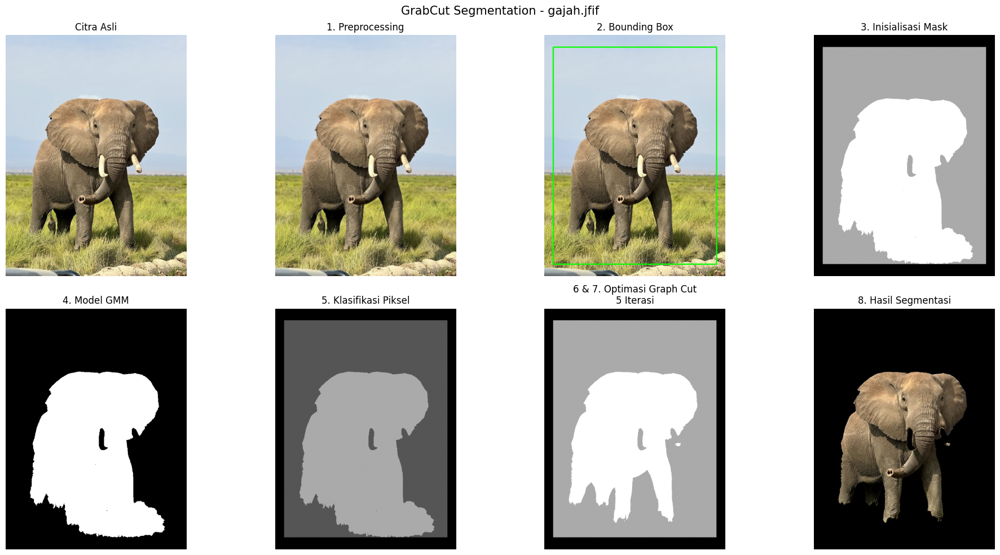

Berhasil menyimpan hasil GrabCut: gajah

Memproses gambar 2: stroberi.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (32, 44, 576, 794)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


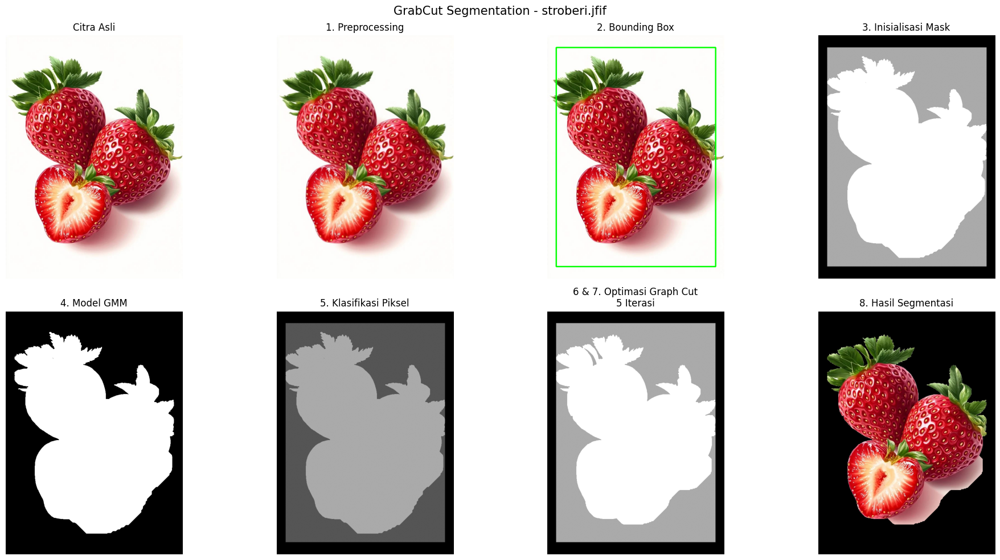

Berhasil menyimpan hasil GrabCut: stroberi

Memproses gambar 3: kucing.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (36, 44, 664, 794)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


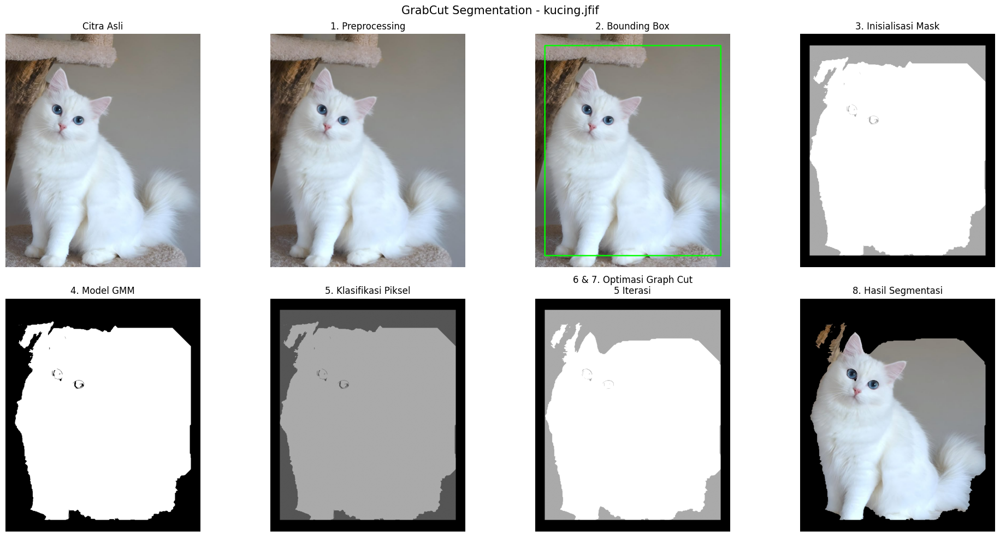

Berhasil menyimpan hasil GrabCut: kucing

Memproses gambar 4: telur.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (24, 34, 435, 616)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


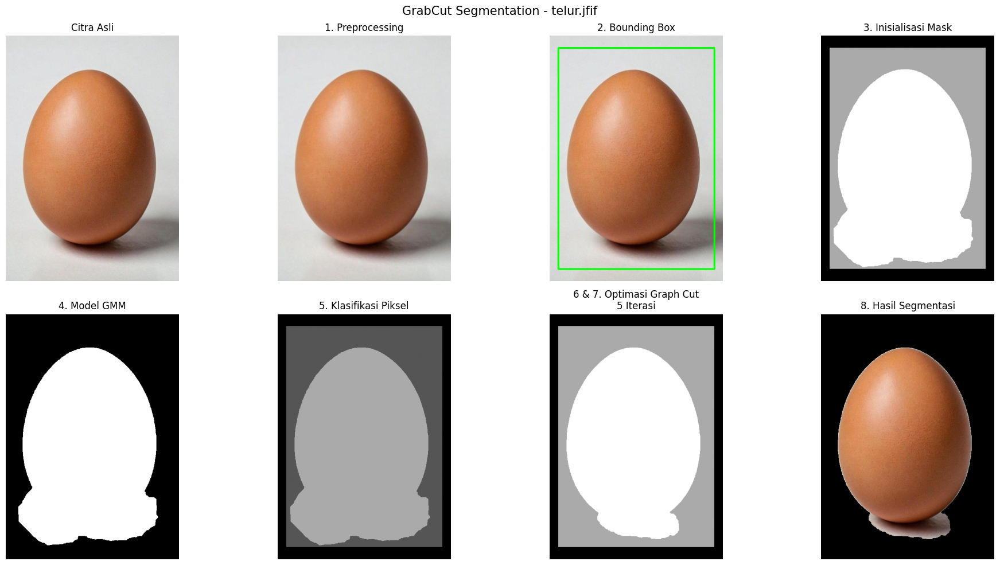

Berhasil menyimpan hasil GrabCut: telur

Memproses gambar 5: Orange.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (36, 64, 664, 1160)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


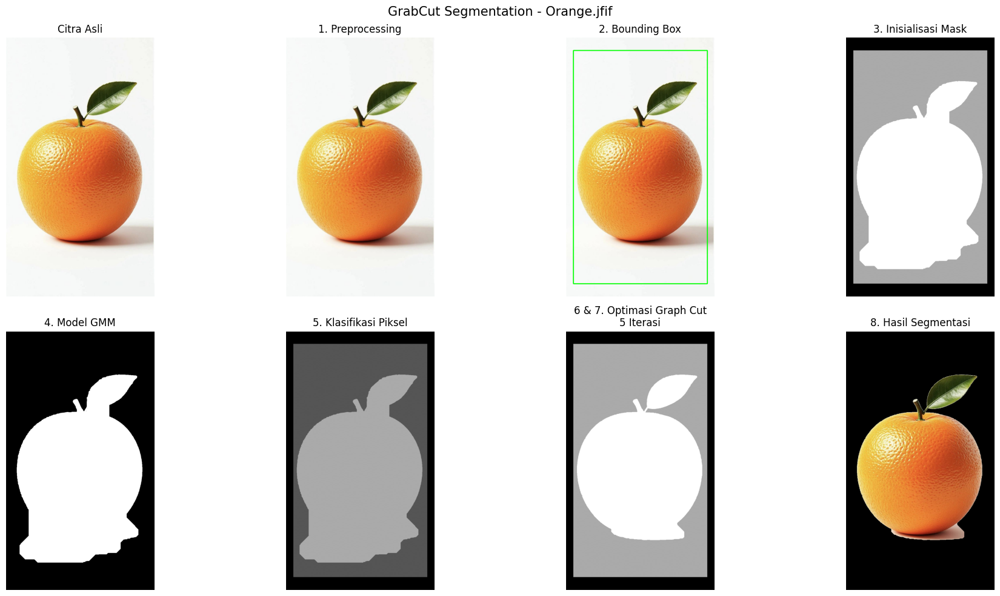

Berhasil menyimpan hasil GrabCut: Orange

Memproses gambar 6: kelinci.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (36, 67, 664, 1216)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


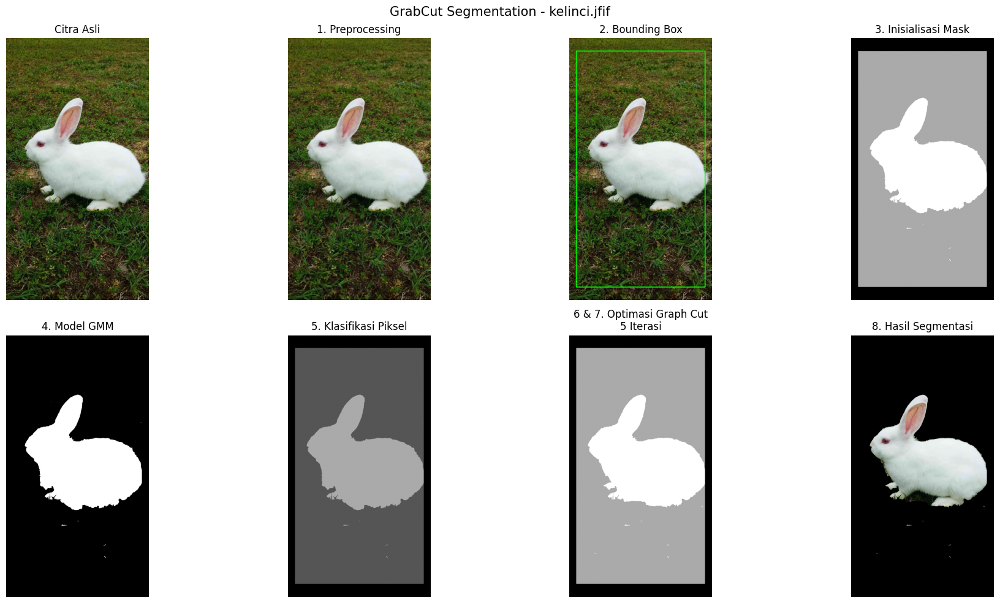

Berhasil menyimpan hasil GrabCut: kelinci

Memproses gambar 7: ayam.jfif

TAHAP 1: Membaca citra dan preprocessing
Grayscale tidak digunakan karena GrabCut
memanfaatkan informasi warna RGB/BGR.

TAHAP 2: Menentukan Bounding Box
Bounding Box: (36, 55, 664, 994)

TAHAP 3: Inisialisasi Foreground dan Background
Inisialisasi mask berhasil.

TAHAP 4: Pemodelan warna menggunakan GMM
Model foreground dan background berhasil dibentuk.

TAHAP 5: Menghitung probabilitas piksel
Estimasi klasifikasi piksel berhasil.

TAHAP 6: Optimasi Graph Cut
Optimasi segmentasi berhasil dilakukan.

TAHAP 7: Pengulangan proses segmentasi
Jumlah iterasi: 5

TAHAP 8: Hasil Segmentasi
Pemisahan foreground dan background selesai.


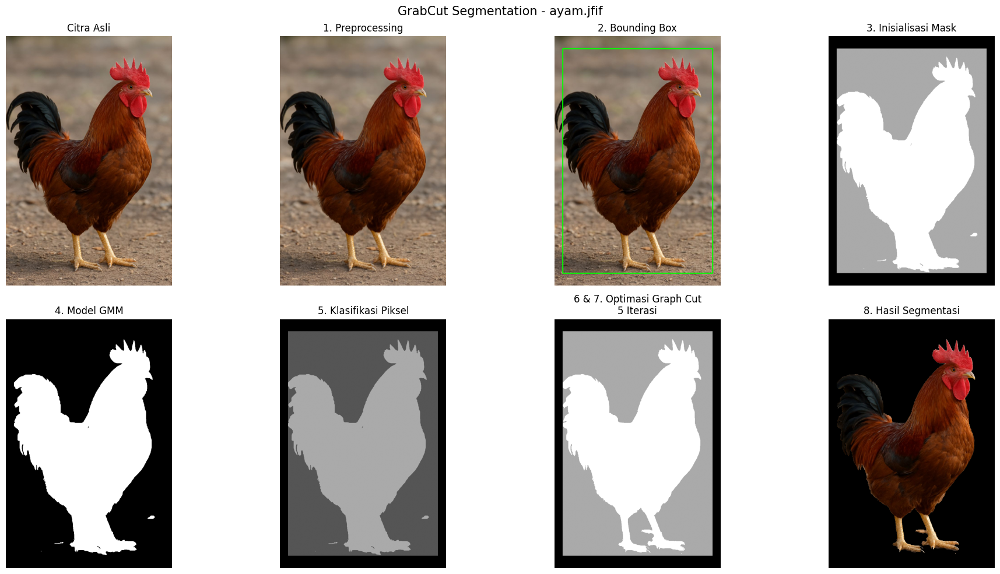

Berhasil menyimpan hasil GrabCut: ayam

SELURUH PROSES GRABCUT SELESAI!
Folder penyimpanan: hasil_grabcut
- kelinci_grabcut.png
- Orange_grabcut.png
- kelinci_tahapan_grabcut.png
- ayam_transparan.png
- kelinci_mask_grabcut.png
- kucing_transparan.png
- gajah_tahapan_grabcut.png
- stroberi_grabcut.png
- gajah_batas_grabcut.png
- kucing_mask_grabcut.png
- gajah_grabcut.png
- Orange_transparan.png
- stroberi_transparan.png
- kelinci_batas_grabcut.png
- stroberi_tahapan_grabcut.png
- Orange_tahapan_grabcut.png
- telur_tahapan_grabcut.png
- telur_transparan.png
- ayam_grabcut.png
- kelinci_transparan.png
- gajah_mask_grabcut.png
- stroberi_batas_grabcut.png
- Orange_mask_grabcut.png
- kucing_tahapan_grabcut.png
- stroberi_mask_grabcut.png
- ayam_mask_grabcut.png
- telur_grabcut.png
- telur_mask_grabcut.png
- gajah_transparan.png
- Orange_batas_grabcut.png
- kucing_batas_grabcut.png
- ayam_batas_grabcut.png
- kucing_grabcut.png
- ayam_tahapan_grabcut.png
- telur_batas_grabcut.png


In [ ]:

# =====================================================
# IMPLEMENTASI 8 TAHAPAN GRABCUT SEGMENTATION
# Disusun untuk Laporan Kelompok 9 - PCD UPN "Veteran" Jatim
# =====================================================

!pip install opencv-python numpy matplotlib gdown -q

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import gdown

# =====================================================
# 1. DOWNLOAD & BACA GAMBAR DARI GOOGLE DRIVE
# =====================================================

folder_url = "https://drive.google.com/drive/folders/1xptupZ5asTHz2t5lAbnC28yO1gNR-_PU?usp=drive_link"

input_folder = "input_gambar_grabcut"
output_folder = "hasil_grabcut"

# Membersihkan folder lama
if os.path.exists(input_folder):
    shutil.rmtree(input_folder)

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

os.makedirs(input_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print("Mengunduh gambar dari Google Drive...")

gdown.download_folder(
    url=folder_url,
    output=input_folder,
    quiet=False,
    use_cookies=False,
    remaining_ok=True
)

format_gambar = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp", ".jfif"
)

daftar_gambar = []

for root, dirs, files in os.walk(input_folder):
    for file in files:
        if file.lower().endswith(format_gambar):
            daftar_gambar.append(os.path.join(root, file))

print("Jumlah gambar ditemukan:", len(daftar_gambar))

if len(daftar_gambar) == 0:
    raise ValueError(
        "Tidak ditemukan gambar. Periksa kembali link Google Drive."
    )


# =====================================================
# 2. FUNGSI GRABCUT BERDASARKAN TAHAPAN TEORI
# =====================================================

def proses_grabcut(img, iterasi=5):

    tinggi, lebar = img.shape[:2]

    # -------------------------------------------------
    # TAHAP 1: MEMBACA CITRA DAN PREPROCESSING
    # -------------------------------------------------

    # Mengurangi noise ringan
    img_blur = cv2.GaussianBlur(img, (3, 3), 0)

    # -------------------------------------------------
    # TAHAP 2: MENENTUKAN BOUNDING BOX
    # -------------------------------------------------

    # Bounding box otomatis dengan margin 5%
    # Diasumsikan objek utama berada di bagian tengah gambar

    margin_x = int(lebar * 0.05)
    margin_y = int(tinggi * 0.05)

    x = margin_x
    y = margin_y
    w = lebar - (2 * margin_x)
    h = tinggi - (2 * margin_y)

    rect = (x, y, w, h)

    # Visualisasi bounding box
    img_bbox = img.copy()

    cv2.rectangle(
        img_bbox,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

    # -------------------------------------------------
    # TAHAP 3: INISIALISASI FOREGROUND DAN BACKGROUND
    # -------------------------------------------------

    # Inisialisasi mask
    mask = np.zeros(
        (tinggi, lebar),
        dtype=np.uint8
    )

    # Model Gaussian Mixture Model
    bgdModel = np.zeros((1, 65), np.float64)
    fgdModel = np.zeros((1, 65), np.float64)

    # Menjalankan inisialisasi GrabCut dengan rectangle
    cv2.grabCut(
        img_blur,
        mask,
        rect,
        bgdModel,
        fgdModel,
        1,
        cv2.GC_INIT_WITH_RECT
    )

    mask_awal = mask.copy()

    # -------------------------------------------------
    # TAHAP 4: PEMODELAN WARNA MENGGUNAKAN GMM
    # -------------------------------------------------

    # Model GMM foreground dan background dibentuk
    # dan diperbarui secara internal oleh OpenCV.

    # Mask hasil inisialisasi
    gmm_visual = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    # -------------------------------------------------
    # TAHAP 5: MENGHITUNG PROBABILITAS PIKSEL
    # -------------------------------------------------

    # Memvisualisasikan klasifikasi piksel berdasarkan
    # hasil estimasi model foreground dan background.

    probabilitas_visual = np.zeros(
        (tinggi, lebar),
        dtype=np.uint8
    )

    probabilitas_visual[mask == cv2.GC_BGD] = 0
    probabilitas_visual[mask == cv2.GC_PR_BGD] = 85
    probabilitas_visual[mask == cv2.GC_PR_FGD] = 170
    probabilitas_visual[mask == cv2.GC_FGD] = 255

    # -------------------------------------------------
    # TAHAP 6 & 7:
    # OPTIMASI GRAPH CUT DAN PENGULANGAN PROSES
    # -------------------------------------------------

    hasil_iterasi = []

    # Menyimpan hasil iterasi pertama
    hasil_iterasi.append(mask.copy())

    for i in range(iterasi - 1):

        # Melakukan optimasi Graph Cut dan pembaruan GMM
        cv2.grabCut(
            img_blur,
            mask,
            None,
            bgdModel,
            fgdModel,
            1,
            cv2.GC_EVAL
        )

        hasil_iterasi.append(mask.copy())

    # Mask akhir hasil GrabCut
    mask_final = np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255,
        0
    ).astype(np.uint8)

    # -------------------------------------------------
    # TAHAP 8: MENGHASILKAN SEGMENTASI CITRA
    # -------------------------------------------------

    # Menghapus background menggunakan mask
    hasil_segmentasi = cv2.bitwise_and(
        img,
        img,
        mask=mask_final
    )

    # Membuat citra transparan
    img_rgba = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2BGRA
    )

    img_rgba[:, :, 3] = mask_final

    # Membuat visualisasi batas objek
    hasil_batas = img.copy()

    contours, _ = cv2.findContours(
        mask_final,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        hasil_batas,
        contours,
        -1,
        (0, 0, 255),
        2
    )

    return (
        img_blur,
        rect,
        img_bbox,
        mask_awal,
        gmm_visual,
        probabilitas_visual,
        hasil_iterasi,
        mask_final,
        hasil_segmentasi,
        img_rgba,
        hasil_batas
    )


# =====================================================
# 3. PROSES SETIAP GAMBAR DALAM LOOPING
# =====================================================

# Parameter GrabCut
jumlah_iterasi = 5

for nomor, nama_file in enumerate(daftar_gambar, start=1):

    print(
        f"\nMemproses gambar {nomor}: "
        f"{os.path.basename(nama_file)}"
    )

    img = cv2.imread(nama_file)

    if img is None:
        print("Gagal membaca gambar, dilewati!")
        continue

    # Menjalankan fungsi GrabCut
    (
        img_blur,
        rect,
        img_bbox,
        mask_awal,
        gmm_visual,
        probabilitas_visual,
        hasil_iterasi,
        mask_final,
        hasil_segmentasi,
        img_rgba,
        hasil_batas
    ) = proses_grabcut(
        img,
        iterasi=jumlah_iterasi
    )

    # -------------------------------------------------
    # MENAMPILKAN TAHAPAN PROSES
    # -------------------------------------------------

    print("\nTAHAP 1: Membaca citra dan preprocessing")
    print("Grayscale tidak digunakan karena GrabCut")
    print("memanfaatkan informasi warna RGB/BGR.")

    print("\nTAHAP 2: Menentukan Bounding Box")
    print("Bounding Box:", rect)

    print("\nTAHAP 3: Inisialisasi Foreground dan Background")
    print("Inisialisasi mask berhasil.")

    print("\nTAHAP 4: Pemodelan warna menggunakan GMM")
    print("Model foreground dan background berhasil dibentuk.")

    print("\nTAHAP 5: Menghitung probabilitas piksel")
    print("Estimasi klasifikasi piksel berhasil.")

    print("\nTAHAP 6: Optimasi Graph Cut")
    print("Optimasi segmentasi berhasil dilakukan.")

    print("\nTAHAP 7: Pengulangan proses segmentasi")
    print("Jumlah iterasi:", jumlah_iterasi)

    print("\nTAHAP 8: Hasil Segmentasi")
    print("Pemisahan foreground dan background selesai.")

    # =================================================
    # 4. VISUALISASI 8 TAHAPAN (MATPLOTLIB)
    # =================================================

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))

    # Citra asli
    axes[0, 0].imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )
    axes[0, 0].set_title("Citra Asli")

    # Tahap 1
    axes[0, 1].imshow(
        cv2.cvtColor(img_blur, cv2.COLOR_BGR2RGB)
    )
    axes[0, 1].set_title("1. Preprocessing")

    # Tahap 2
    axes[0, 2].imshow(
        cv2.cvtColor(img_bbox, cv2.COLOR_BGR2RGB)
    )
    axes[0, 2].set_title("2. Bounding Box")

    # Tahap 3
    axes[0, 3].imshow(mask_awal, cmap="gray")
    axes[0, 3].set_title("3. Inisialisasi Mask")

    # Tahap 4
    axes[1, 0].imshow(gmm_visual, cmap="gray")
    axes[1, 0].set_title("4. Model GMM")

    # Tahap 5
    axes[1, 1].imshow(
        probabilitas_visual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, 1].set_title("5. Klasifikasi Piksel")

    # Tahap 6 dan 7
    axes[1, 2].imshow(
        hasil_iterasi[-1],
        cmap="gray"
    )
    axes[1, 2].set_title(
        f"6 & 7. Optimasi Graph Cut\n"
        f"{jumlah_iterasi} Iterasi"
    )

    # Tahap 8
    axes[1, 3].imshow(
        cv2.cvtColor(
            hasil_segmentasi,
            cv2.COLOR_BGR2RGB
        )
    )
    axes[1, 3].set_title("8. Hasil Segmentasi")

    for ax in axes.flatten():
        ax.axis("off")

    plt.suptitle(
        "GrabCut Segmentation - "
        + os.path.basename(nama_file),
        fontsize=15
    )

    plt.tight_layout()

    # =================================================
    # 5. MENYIMPAN HASIL AKHIR
    # =================================================

    nama_dasar = os.path.splitext(
        os.path.basename(nama_file)
    )[0]

    # Menyimpan hasil segmentasi
    path_hasil = os.path.join(
        output_folder,
        f"{nama_dasar}_grabcut.png"
    )

    cv2.imwrite(
        path_hasil,
        hasil_segmentasi
    )

    # Menyimpan mask
    path_mask = os.path.join(
        output_folder,
        f"{nama_dasar}_mask_grabcut.png"
    )

    cv2.imwrite(
        path_mask,
        mask_final
    )

    # Menyimpan gambar transparan
    path_transparan = os.path.join(
        output_folder,
        f"{nama_dasar}_transparan.png"
    )

    cv2.imwrite(
        path_transparan,
        img_rgba
    )

    # Menyimpan hasil dengan garis batas objek
    path_batas = os.path.join(
        output_folder,
        f"{nama_dasar}_batas_grabcut.png"
    )

    cv2.imwrite(
        path_batas,
        hasil_batas
    )

    # Menyimpan visualisasi tahapan
    path_visual = os.path.join(
        output_folder,
        f"{nama_dasar}_tahapan_grabcut.png"
    )

    fig.savefig(
        path_visual,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(
        "Berhasil menyimpan hasil GrabCut:",
        nama_dasar
    )


# =====================================================
# 6. SELESAI
# =====================================================

print("\n====================================")
print("SELURUH PROSES GRABCUT SELESAI!")
print("====================================")

print("Folder penyimpanan:", output_folder)

for file in os.listdir(output_folder):
    print("-", file)
